# Test completion funnel: fulfillment & sample return EDA

Uses the `funnel_pkg` package. Set `USE_DEMO = False` to query the live (read-only) staging database; with `True` it runs on
**synthetic** data so the notebook works anywhere. Every chart carries the note *Staging data; may include testing records.*

**Method in brief**
1. Count unique paying customers at each stage, using only dates that are trustworthy (order status history, result history).
2. Exclude replacement orders and bulk accounts (10+ orders) from the funnel, then study replacements separately.
3. Audit the date columns before using them for timing: bulk-stamped dates are flagged, not trusted.
4. Check for test accounts and bursts, because staging is not production.

In [1]:
%matplotlib inline
import pandas as pd
from IPython.display import display  # noqa

from funnel_pkg import Config, Database, FunnelData, FunnelEDA, FunnelPlots
from funnel_pkg.demo import DemoData

USE_DEMO = True  # False = live staging database (needs a .env with ADYN_POSTGRES_* in this folder)
ENV_FILE = ".env"
COHORT_START, COHORT_END = "2023-01-01", "2024-01-01"

cfg = Config()
if USE_DEMO:
    data = DemoData(cfg=cfg)
else:
    db = Database(env_file=ENV_FILE)
    data = FunnelData(db, cfg)
eda = FunnelEDA(data, cfg)
plots = FunnelPlots(eda)
pd.set_option("display.width", 140)
print("customers analysed:", len(eda.customers), "| bulk accounts excluded:", len(eda.bulk_accounts))

customers analysed: 894 | bulk accounts excluded: 6


## 1. Funnel: where do paying customers drop off?

,stage,customers,pct_of_prev,pct_of_paid,lost_vs_prev
0,Account created,894,NaN,NaN,NaN
1,Paid order,894,100.0,100.0,0.0
2,Sent to Allied,248,27.7,27.7,646.0
3,Kit shipped (left Allied),217,87.5,24.3,31.0
4,Sample received by lab,189,87.1,21.1,28.0
5,Result created,146,77.2,16.3,43.0
6,Result approved,123,84.2,13.8,23.0
7,Result viewed,103,83.7,11.5,20.0


{'stage': 'Sent to Allied', 'lost': 646}


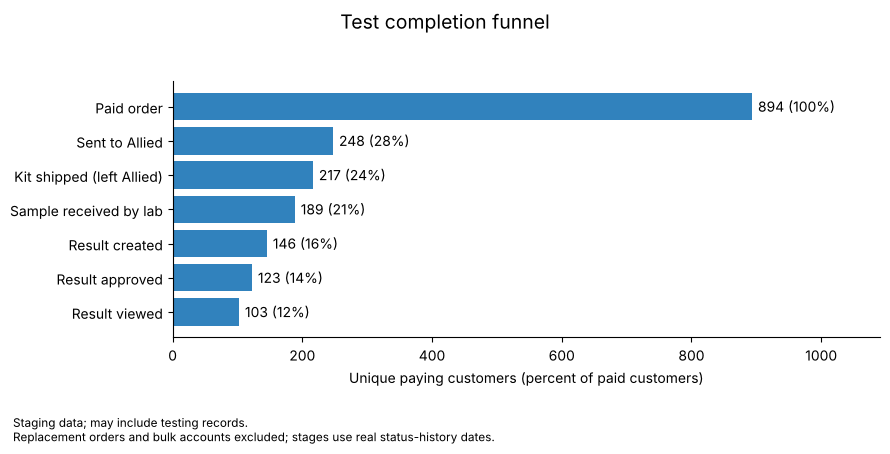

In [2]:
display(eda.funnel()); print(eda.largest_drop()); plots.funnel()

Replacement orders and bulk accounts are excluded. The largest loss is at the hand-off to fulfillment (paid to *Sent to Allied*).

## 2. Which dates can we trust for timing?

,table_name,column_name,n_dates,n_on_busiest_day,distinct_days,share_on_busiest_day
0,orders,date_order_paid,900,36,300,4.0
1,orders,activation_date,900,495,300,55.0
2,orders,allied_order_date,900,630,300,70.0
3,shipments,date_shipped,900,558,300,62.0
4,shipments,delivered_to_customer_date,900,765,300,85.0
5,shipments,delivered_to_facility1_date,900,720,300,80.0
6,samples,received_by_lab_date,900,27,300,3.0
7,samples,processed_by_lab_date,900,45,300,5.0
8,resultvalues,created_date,900,54,300,6.0
9,resultvalues,customer_viewed_date,900,81,300,9.0


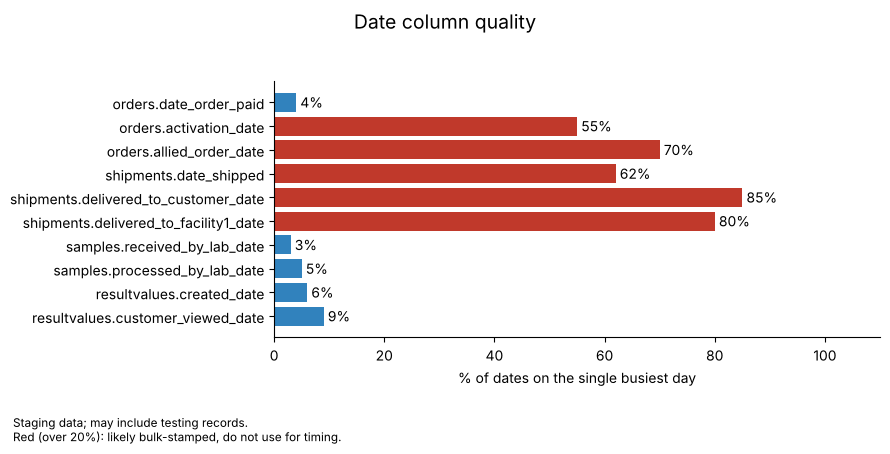

In [3]:
display(eda.date_quality()); plots.date_quality()

A date column where most values fall on one day was stamped in bulk (a migration or batch job), so it cannot describe real timing.

,from,to,n,median_days,p25,p75,pct_negative
0,created_date,first_paid,894,2.0,1.0,3.0,0.0
1,first_paid,sent_to_allied,248,2.0,1.0,3.0,0.0
2,sent_to_allied,shipped,217,6.0,3.0,9.0,2.3
3,first_paid,shipped,217,8.0,5.0,11.0,0.0
4,shipped,lab_received,189,6.0,4.0,8.0,0.0
5,lab_processed,result_created,146,9.0,5.0,13.0,3.4
6,result_created,result_approved_date,123,1.0,-3.0,6.0,41.5
7,result_approved_date,result_viewed,103,8.0,0.0,13.0,23.3
8,result_created,result_viewed,103,8.0,0.5,13.5,22.3
9,first_paid,result_viewed,103,32.0,24.5,39.0,0.0


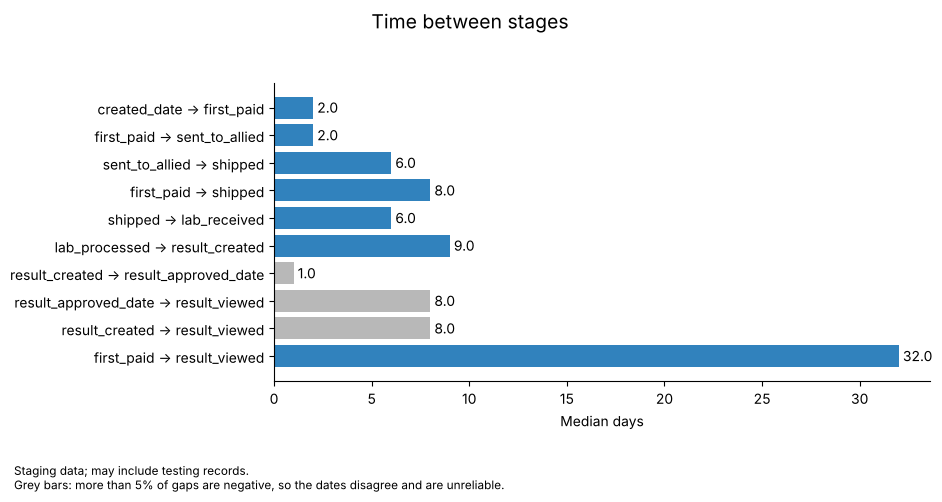

In [4]:
display(eda.stage_gaps()); plots.stage_gaps()

Gaps with many negative values mean the two dates disagree about the order of events; grey bars (more than 5% negative) are unreliable.

,step,n,p25,p50,p75,p90,negative,over_90_days
0,paid -> shipped,218,4.0,8.0,20.0,60.0,0.0,NaN
1,shipped -> lab received,190,-30.0,-5.0,3.0,9.0,142.0,0.0
2,lab received -> result created,147,1.0,4.0,9.0,18.0,NaN,NaN
3,result created -> approved,124,0.0,1.0,2.0,5.0,NaN,NaN


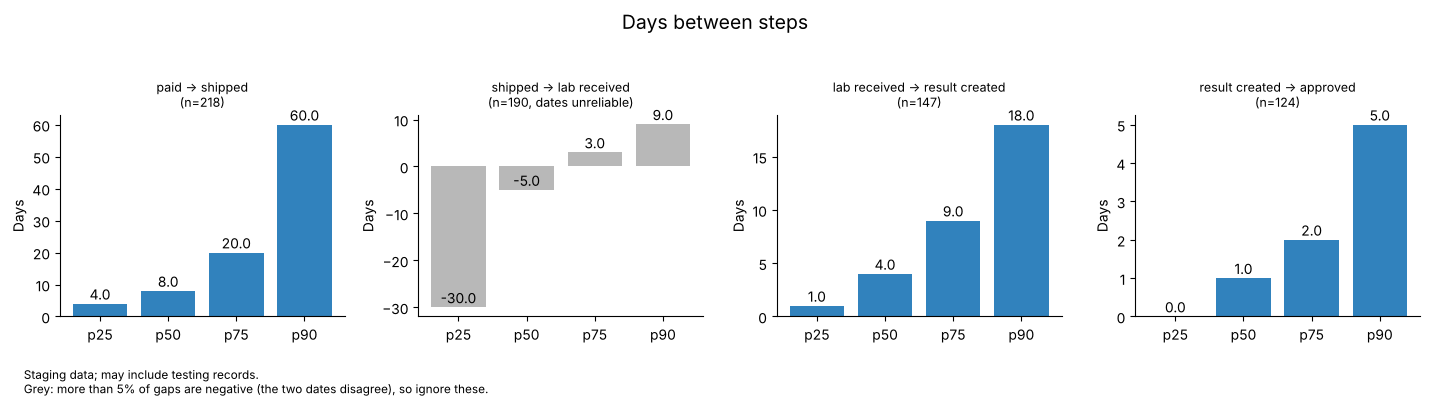

In [5]:
display(eda.timing_steps()); plots.timing_steps()

## 3. Who ships and who views results?

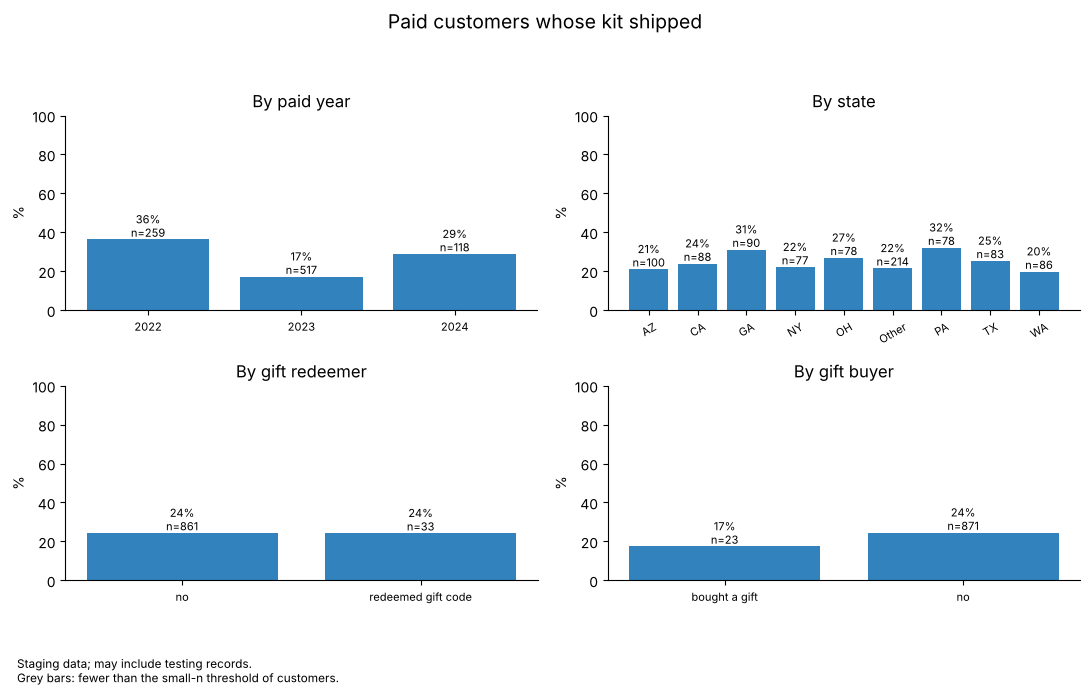

In [6]:
plots.ship_rates()

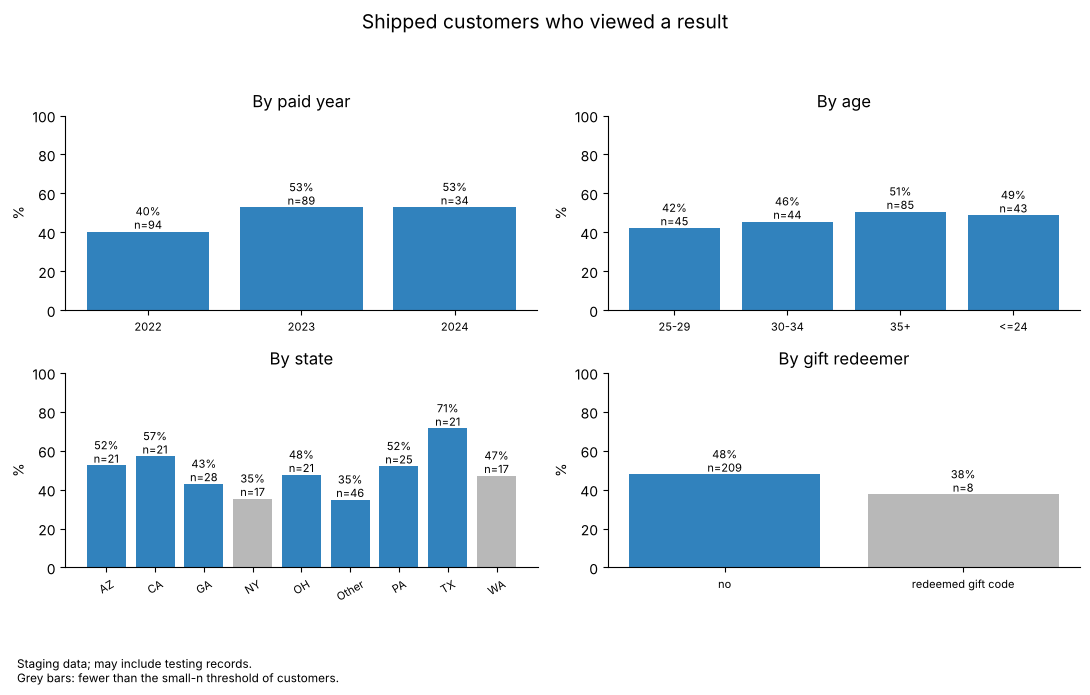

In [7]:
plots.viewed_rates()

Grey bars have fewer than `cfg.small_n` customers, so read them as noise.

## 4. Is the staging data clean enough to trust? Test accounts and bursts

,accounts,orders,reserved_orders,shipped_orders
0,60,70,65,2


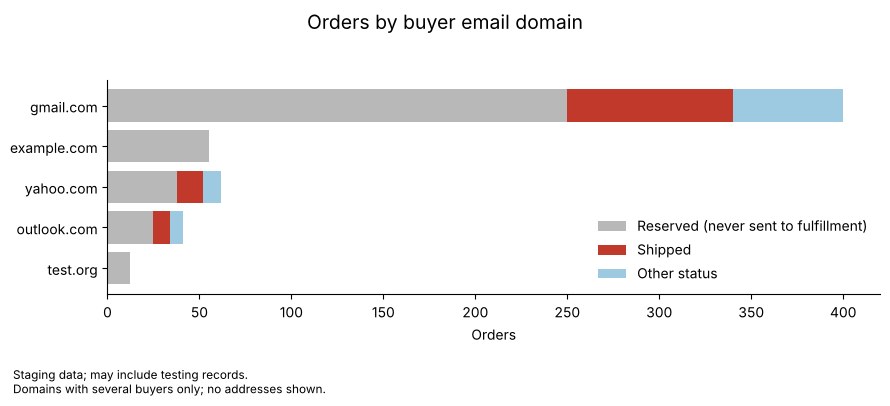

In [8]:
display(eda.test_like_accounts()); plots.email_domains()

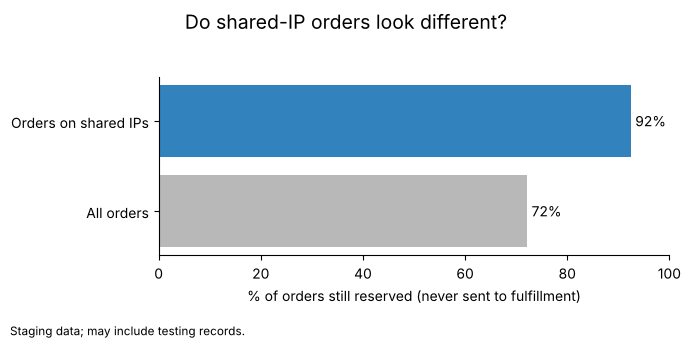

In [9]:
plots.shared_ip_summary()

,paid_month,paid,profile_done,shipped,pct_profile,pct_shipped
0,2023-01-01,16,4,4,25.0,25.0
1,2023-02-01,159,54,10,34.0,6.3
2,2023-03-01,26,11,6,42.3,23.1
3,2023-04-01,20,3,9,15.0,45.0
4,2023-05-01,22,7,9,31.8,40.9
5,2023-06-01,24,8,13,33.3,54.2
6,2023-07-01,143,46,6,32.2,4.2
7,2023-08-01,33,8,9,24.2,27.3
8,2023-09-01,15,2,2,13.3,13.3
9,2023-10-01,25,7,9,28.0,36.0


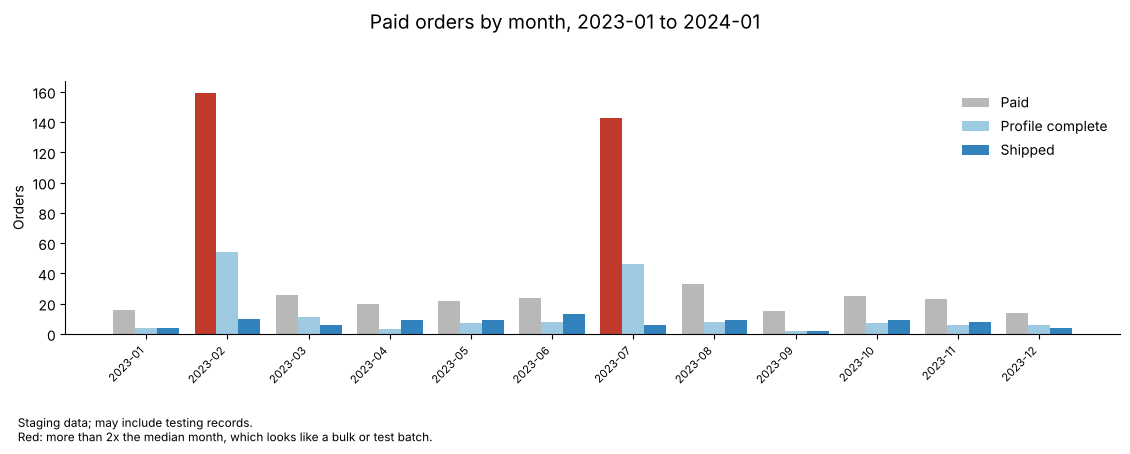

In [10]:
display(eda.cohort_by_month(COHORT_START, COHORT_END)); plots.cohort_by_month(COHORT_START, COHORT_END)

Months far above the median with a low shipped share look like bulk or test batches, not organic demand.

## 5. Blocking steps between payment and shipping

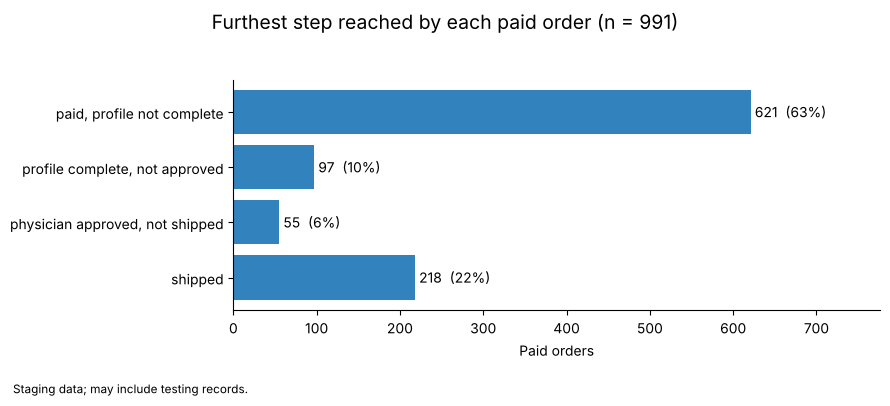

In [11]:
plots.furthest_step()

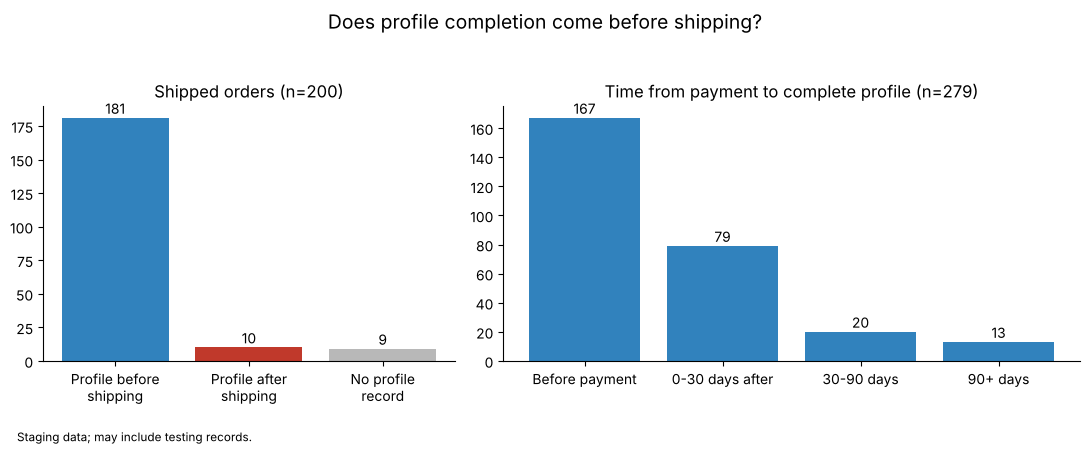

In [12]:
plots.profile_sequence()

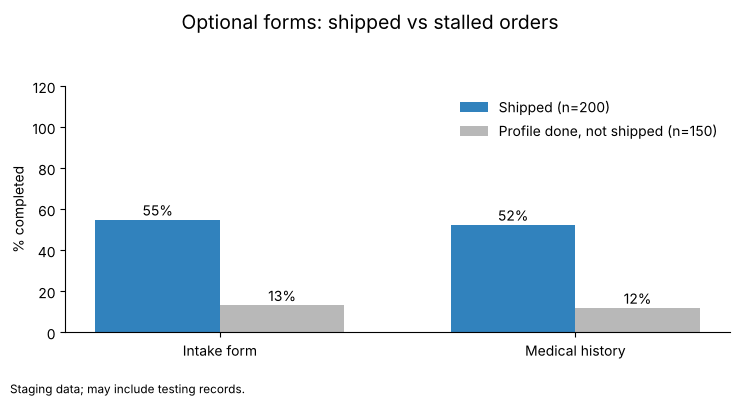

In [13]:
plots.optional_forms()

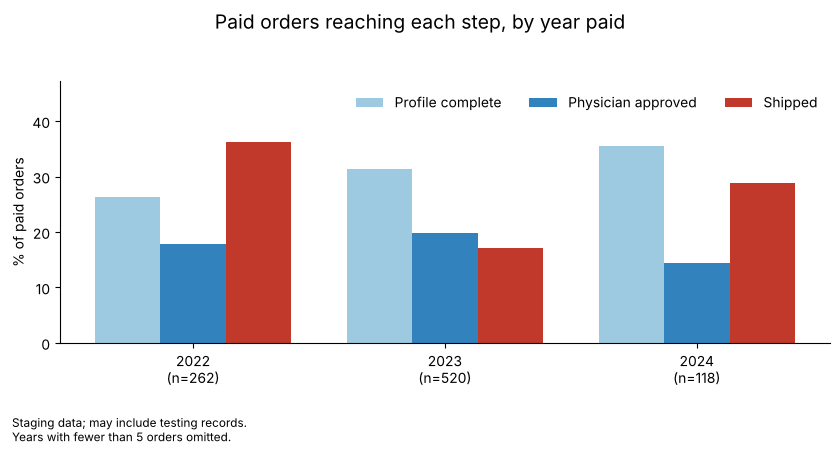

In [14]:
plots.steps_by_year()

## 6. Replacement kits and sample quality

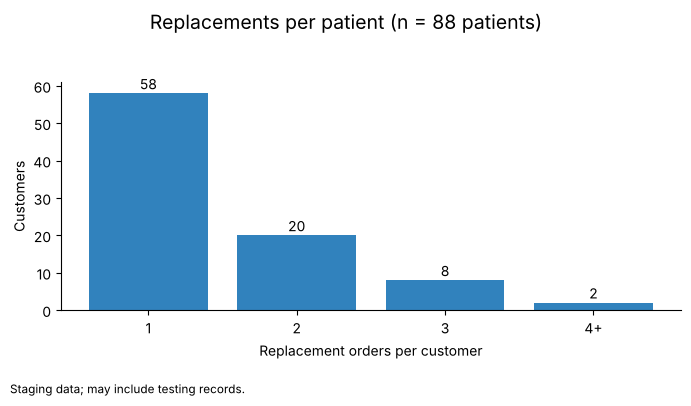

In [15]:
plots.replacements_per_customer()

,reason_class,records
0,placeholder / test text,105
1,"structured (lab, mail, customer)",33
2,other / unclear,12


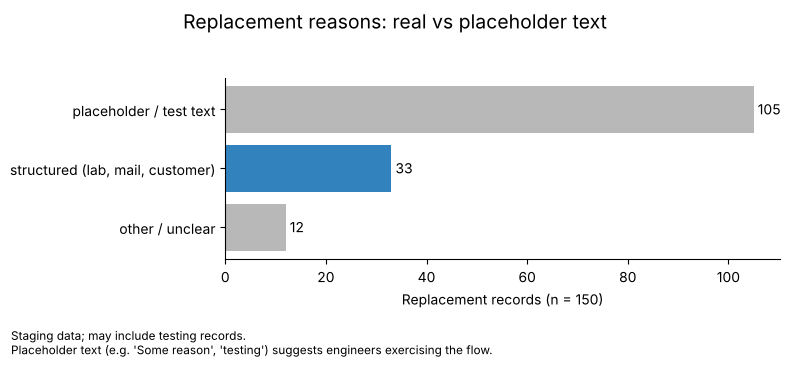

In [16]:
display(eda.replacement_reason_classes()); plots.replacement_reasons()

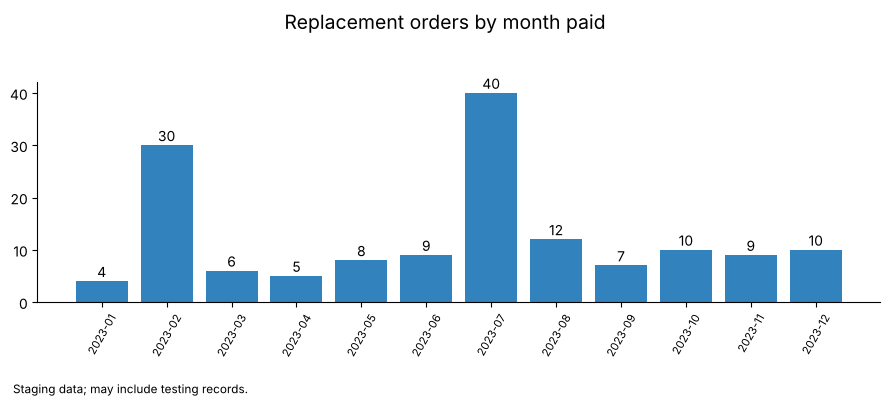

In [17]:
plots.replacements_by_month()

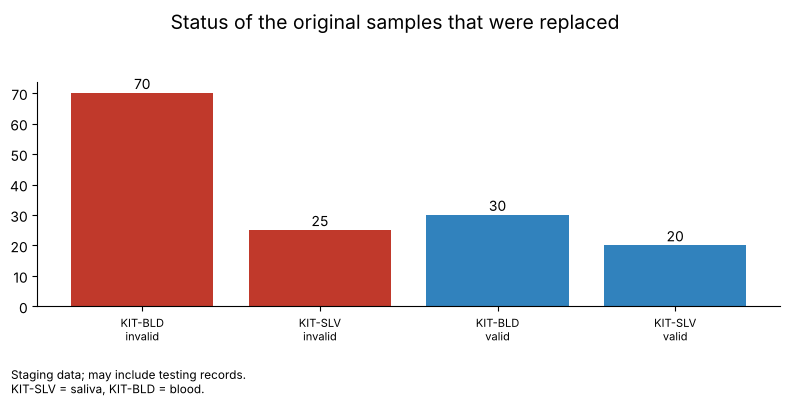

In [18]:
plots.replaced_sample_status()

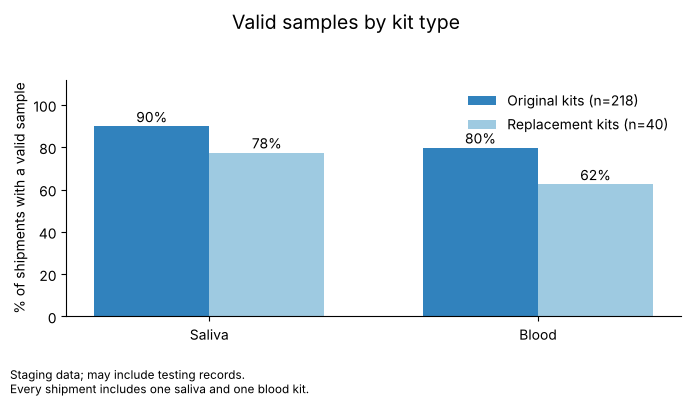

In [19]:
plots.kit_outcomes()

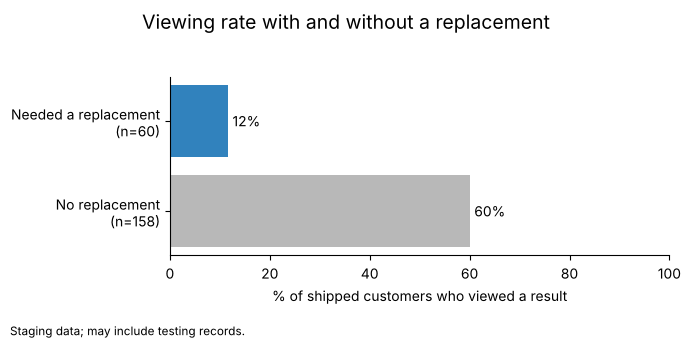

In [20]:
plots.replacement_vs_viewing()

## 7. Save everything
Writes every chart (PNG) and the table behind it (CSV), the same as `python make_plots.py`.

In [21]:
from pathlib import Path
out = Path("demo_output" if USE_DEMO else "output")
(out / "charts").mkdir(parents=True, exist_ok=True); (out / "tables").mkdir(parents=True, exist_ok=True)
for name, table in eda.tables(COHORT_START, COHORT_END).items():
    table.to_csv(out / "tables" / f"{name}.csv", index=False)
for name, fig in plots.all(COHORT_START, COHORT_END).items():
    fig.savefig(out / "charts" / f"{name}.png", dpi=150)
print("saved to", out.resolve())

saved to /tmp/claude-0/-home-claude/e602ac81-3925-5bf7-b1ae-da1bf88b769e/scratchpad/pkg2/funnel_python/demo_output
